# Treinamento do Modelo — Manutenção Preditiva na Indústria 4.0 (Fase 1)

### Contexto do Negócio e Problema
Na indústria moderna (Indústria 4.0), a parada não programada de linhas de produção decorrente da quebra inesperada de maquinários causa prejuízos financeiros substanciais, desperdício de insumos e riscos operacionais. O objetivo deste projeto é construir um modelo preditivo capaz de monitorar variáveis telemétricas de sensores industriais e **prever com antecedência a iminência de falhas mecânicas**, viabilizando intervenções preditivas antes que o dano catastrófico ocorra.

* **Problema:** Classificação binária para predição de falhas em máquinas industriais.
* **Variável Alvo (Target):** `falha_maquina` (0 = operação normal, 1 = máquina com falha).
* **Artefato Final:** Pipeline completo serializado contendo pré-processamento, tratamento de dados faltantes, balanceamento com SMOTE e classificador supervisionado.

## 1. Importações de Bibliotecas
Importamos as ferramentas essenciais para manipulação de dados, computação numérica, pré-processamento scikit-learn, balanceamento com imbalanced-learn e avaliação de métricas.

In [1]:
import json
import os
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Configurações de visualização
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 11

## 2. Carga dos Dados

Carregamos o dataset através do **caminho relativo** `../data/manutencao_preditiva.csv`, garantindo estrita reprodutibilidade sem dependência de diretórios locais absolutos.

In [2]:
DATA_PATH = "../data/manutencao_preditiva.csv"
df = pd.read_csv(DATA_PATH)
print(f"Dimensões do dataset original: {df.shape[0]} linhas x {df.shape[1]} colunas")
df.head()

Dimensões do dataset original: 10000 linhas x 14 colunas


,udi,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
0,1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0
3,4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0


## 3. Conferência e Análise Diagnóstica dos Dados

### O que os dados revelam:
1. **Valores Ausentes:** Há exatamente 500 registros nulos em cada um dos 4 sensores numéricos (`temperatura_ar_k`, `temperatura_processo_k`, `velocidade_rotacao_rpm`, `torque_nm`), correspondendo a 5% de cada coluna. Notavelmente, tratam-se exatamente das **mesmas 500 linhas** (uma leitura inteira de telemetria perdida simultaneamente). A taxa de falha nessas 500 linhas é de 3,4%, perfeitamente idêntica à taxa global da base, indicando que os nulos ocorrem ao acaso (MCAR — *Missing Completely at Random*). Logo, a **imputação pela mediana** é estatisticamente consistente e segura.
2. **Atributo Categórico:** A coluna `tipo` representa as variantes de produto (L = 60%, M = 30%, H = 10%). Exige transformação em variáveis numéricas através de `OneHotEncoder(handle_unknown='ignore')`.
3. **Disparidade de Escalas:** A velocidade de rotação média (~1.539 rpm) é cerca de 38 vezes maior em grandeza do que o torque médio (~40 Nm). Essa assimetria exige escalonamento (`StandardScaler`) para algoritmos sensíveis à escala e garante estabilidade numérica global.
4. **Desbalanceamento Severo de Classes:** Apenas 3,4% das instâncias (339 máquinas) apresentam falha contra 9.661 em operação normal. Classificadores tradicionais tenderiam a prever sempre a classe majoritária (acurácia cega de 96,6%). Por isso, utilizaremos **SMOTE (*Synthetic Minority Over-sampling Technique*)** acoplado no pipeline de treino.

In [3]:
print("--- Tipos de dados e valores nulos ---")
display_info = pd.DataFrame({
    "Tipo": df.dtypes,
    "Valores Nulos": df.isnull().sum(),
    "% Nulos": (df.isnull().sum() / len(df)) * 100
})
print(display_info)

print("\n--- Distribuição da coluna categórica 'tipo' ---")
print(df["tipo"].value_counts(normalize=True).round(4) * 100)

print("\n--- Distribuição da classe alvo 'falha_maquina' ---")
print(df["falha_maquina"].value_counts())
print(f"Proporção de falhas: {df['falha_maquina'].mean() * 100:.2f}%")

print("\n--- Estatísticas descritivas dos sensores ---")
sensor_cols = [
    "temperatura_ar_k", "temperatura_processo_k",
    "velocidade_rotacao_rpm", "torque_nm", "desgaste_ferramenta_min"
]
df[sensor_cols].describe().round(2)

--- Tipos de dados e valores nulos ---
                            Tipo  Valores Nulos  % Nulos
udi                        int64              0      0.0
id_produto                   str              0      0.0
tipo                         str              0      0.0
temperatura_ar_k         float64            500      5.0
temperatura_processo_k   float64            500      5.0
velocidade_rotacao_rpm   float64            500      5.0
torque_nm                float64            500      5.0
desgaste_ferramenta_min    int64              0      0.0
falha_maquina              int64              0      0.0
falha_twf                  int64              0      0.0
falha_hdf                  int64              0      0.0
falha_pwf                  int64              0      0.0
falha_osf                  int64              0      0.0
falha_rnf                  int64              0      0.0

--- Distribuição da coluna categórica 'tipo' ---
tipo
L    60.00
M    29.97
H    10.03
Name: proportion, 

,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min
count,9500.0,9500.00,9500.00,9500.00,10000.00
mean,300.0,310.00,1539.25,39.97,107.95
std,2.0,1.49,180.27,10.00,63.65
min,295.3,305.70,1168.00,3.80,0.00
25%,298.3,308.80,1423.00,33.10,53.00
50%,300.1,310.10,1504.00,40.10,108.00
75%,301.5,311.10,1613.00,46.70,162.00
max,304.5,313.80,2886.00,76.60,253.00


## 4. Separação de Features (X) e Alvo (y)

### Justificativa de Descarte de Colunas:
* **Identificadores Únicos (`udi`, `id_produto`):** São chaves primárias e códigos seriais sem correlação física ou mecânica com a degradação dos componentes. Mantê-los causaria memorização indevida (*overfitting*).
* **Vazamento de Dados (*Data Leakage* — `falha_twf`, `falha_hdf`, `falha_pwf`, `falha_osf`, `falha_rnf`):** Estas colunas rotulam o modo específico da falha (ex.: falha por sobrecarga, dissipação de calor, desgaste de ferramenta). Elas só são registradas após a ocorrência confirmada da falha. Usá-las para inferir `falha_maquina` caracterizaria vazamento direto do alvo.

In [4]:
cols_identificadores = ["udi", "id_produto"]
cols_leakage = ["falha_twf", "falha_hdf", "falha_pwf", "falha_osf", "falha_rnf"]
cols_remover = cols_identificadores + cols_leakage

df_modelagem = df.drop(columns=cols_remover)
X = df_modelagem.drop(columns=["falha_maquina"])
y = df_modelagem["falha_maquina"]

print(f"Features selecionadas ({X.shape[1]} colunas): {list(X.columns)}")
print(f"Dimensões finais de X: {X.shape}")
print(f"Dimensões finais de y: {y.shape}")

Features selecionadas (6 colunas): ['tipo', 'temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min']
Dimensões finais de X: (10000, 6)
Dimensões finais de y: (10000,)


## 5. Divisão Estratificada: Treino, Validação e Teste (60/20/20)

### Metodologia de Particionamento:
A divisão rigorosa em três subconjuntos é fundamental para a integridade científica do modelo:
1. **Treino (60%):** Utilizado para o ajuste matemático dos parâmetros dos modelos e aprendizado do pré-processamento (medianas, médias, desvios e categorias).
2. **Validação (20%):** Utilizado exclusivamente para comparar os diferentes algoritmos candidatos e ajustar hiperparâmetros sem contaminar o teste.
3. **Teste (20%):** Reservado e avaliado **uma única vez** sobre o modelo final escolhido, simulando o ambiente real de produção.

O parâmetro `stratify=y` preserva a proporção idêntica de 3,4% de falhas nos três conjuntos, e a semente fixa `random_state=42` garante reprodutibilidade integral.

In [5]:
# 1º split: isola 20% para teste final e 80% temporário
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 2º split: da fatia temporária (80%), reserva 25% para validação (0.25 * 0.80 = 20%) e 75% para treino (60%)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

## 6. Conferência dos Conjuntos de Dados

Verificamos o tamanho absoluto e a taxa percentual de falhas em cada partição para atestar a estratificação.

In [6]:
split_summary = pd.DataFrame({
    "Partição": ["Treino", "Validação", "Teste", "Total"],
    "Amostras": [len(X_train), len(X_val), len(X_test), len(df)],
    "Proporção (%)": [
        len(X_train) / len(df) * 100,
        len(X_val) / len(df) * 100,
        len(X_test) / len(df) * 100,
        100.0,
    ],
    "Falhas (Qtd)": [y_train.sum(), y_val.sum(), y_test.sum(), y.sum()],
    "Taxa de Falha (%)": [
        y_train.mean() * 100,
        y_val.mean() * 100,
        y_test.mean() * 100,
        y.mean() * 100,
    ],
})
split_summary.round(2)

,Partição,Amostras,Proporção (%),Falhas (Qtd),Taxa de Falha (%)
0,Treino,6000,60.0,203,3.38
1,Validação,2000,20.0,68,3.40
2,Teste,2000,20.0,68,3.40
3,Total,10000,100.0,339,3.39


## 7. Construção do Pipeline de Pré-processamento e Balanceamento

### Arquitetura do Pipeline (`imblearn.pipeline.Pipeline`):
Para evitar *training-serving skew* (divergência entre o treinamento e a inferência em produção), encapsulamos todo o tratamento em um objeto unificado:
* **Ramo Numérico:** `SimpleImputer(strategy='median')` para preenchimento dos nulos, seguido de `StandardScaler()` para normalização dos sensores.
* **Ramo Categórico:** `OneHotEncoder(handle_unknown='ignore')` para a variável `tipo`.
* **Balanceamento Sintético (SMOTE):** Inserido dentro do pipeline do `imblearn`. O SMOTE atua **estritamente durante a chamada do método `fit()`** (conjunto de treino) e é automaticamente inativo durante chamadas de `predict()` e `predict_proba()`. Isso impede contaminação dos dados de teste e da API.

In [7]:
colunas_numericas = [
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
    "desgaste_ferramenta_min",
]
colunas_categoricas = ["tipo"]

transformador_numerico = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

transformador_categorico = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", transformador_numerico, colunas_numericas),
        ("cat", transformador_categorico, colunas_categoricas),
    ]
)
print("Preprocessor configurado com sucesso:")
preprocessor

Preprocessor configurado com sucesso:


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## 8. Comparação de Algoritmos Candidatos no Conjunto de Validação

Treinamos e comparamos 3 famílias de classificadores:
1. **Regressão Logística:** Modelo linear basal de referência (*baseline*).
2. **Árvore de Decisão (`max_depth=5`):** Modelo baseado em regras determinísticas e de alta explicabilidade.
3. **Random Forest (`n_estimators=100, max_depth=6`):** Modelo de ensemble bagging, altamente robusto contra ruídos e overfitting.

### Métrica de Decisão Prioritária:
Em Manutenção Preditiva, o custo de um **Falso Negativo** (uma máquina que quebra sem alerta prévio, paralisando a fábrica) é ordens de grandeza superior ao de um Falso Positivo (uma inspeção preventiva desnecessária). Portanto, as métricas prioritárias de seleção são **Recall da classe 1** e **ROC-AUC**, ponderadas com um **F1-Score** equilibrado.

In [8]:
modelos_candidatos = {
    "Regressão Logística": LogisticRegression(max_iter=1000, random_state=42),
    "Árvore de Decisão (max_depth=5)": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest (max_depth=6)": RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42),
}

resultados_validacao = {}

for nome, clf in modelos_candidatos.items():
    pipe = ImbPipeline([
        ("preprocessor", clone(preprocessor)),  # cópia nova para cada candidato
        ("smote", SMOTE(random_state=42)),
        ("classifier", clf),
    ])
    
    # Ajuste exclusivo nos dados de treino
    pipe.fit(X_train, y_train)
    
    # Predições no conjunto de validação
    y_pred_val = pipe.predict(X_val)
    y_proba_val = pipe.predict_proba(X_val)[:, 1]
    
    acc = accuracy_score(y_val, y_pred_val)
    rec = recall_score(y_val, y_pred_val)
    prec = precision_score(y_val, y_pred_val)
    f1 = f1_score(y_val, y_pred_val)
    auc = roc_auc_score(y_val, y_proba_val)
    
    resultados_validacao[nome] = {
        "Acurácia": acc,
        "Recall (Falha)": rec,
        "Precisão": prec,
        "F1-Score": f1,
        "ROC-AUC": auc,
        "pipeline": pipe,
    }

tabela_validacao = pd.DataFrame(resultados_validacao).T.drop(columns=["pipeline"])
print("--- Tabela Comparativa na Validação ---")
tabela_validacao.round(4)

--- Tabela Comparativa na Validação ---


,Acurácia,Recall (Falha),Precisão,F1-Score,ROC-AUC
Regressão Logística,0.818,0.823529,0.137255,0.235294,0.877603
Árvore de Decisão (max_depth=5),0.9215,0.911765,0.29108,0.441281,0.928644
Random Forest (max_depth=6),0.919,0.794118,0.267327,0.4,0.956099


## 9. Avaliação Final do Modelo Selecionado no Conjunto de Teste

### Escolha Técnica:
O modelo **Random Forest** foi selecionado como o classificador definitivo para produção:
* Apresentou o **maior poder discriminatório global** no conjunto de validação (**ROC-AUC de 0.956**).
* Excelente capacidade de captura de falhas com **Recall superior a 79%**, minimizando paradas imprevistas de máquinas.
* Arquitetura em *ensemble* que mitiga a variância de árvores individuais, oferecendo maior robustez a variações de sensores industriais em campo.

Procedemos agora com a **avaliação final de integridade sobre o conjunto de teste não contaminado**.

RELATÓRIO DE DESEMPENHO NO TESTE — Random Forest (max_depth=6)
Acurácia:        0.9385
Recall (Falha):  0.7647
Precisão:        0.3270
F1-Score:        0.4581
ROC-AUC:         0.9338

Relatório de Classificação Detalhado:
                 precision    recall  f1-score   support

Operação Normal       0.99      0.94      0.97      1932
          Falha       0.33      0.76      0.46        68

       accuracy                           0.94      2000
      macro avg       0.66      0.85      0.71      2000
   weighted avg       0.97      0.94      0.95      2000



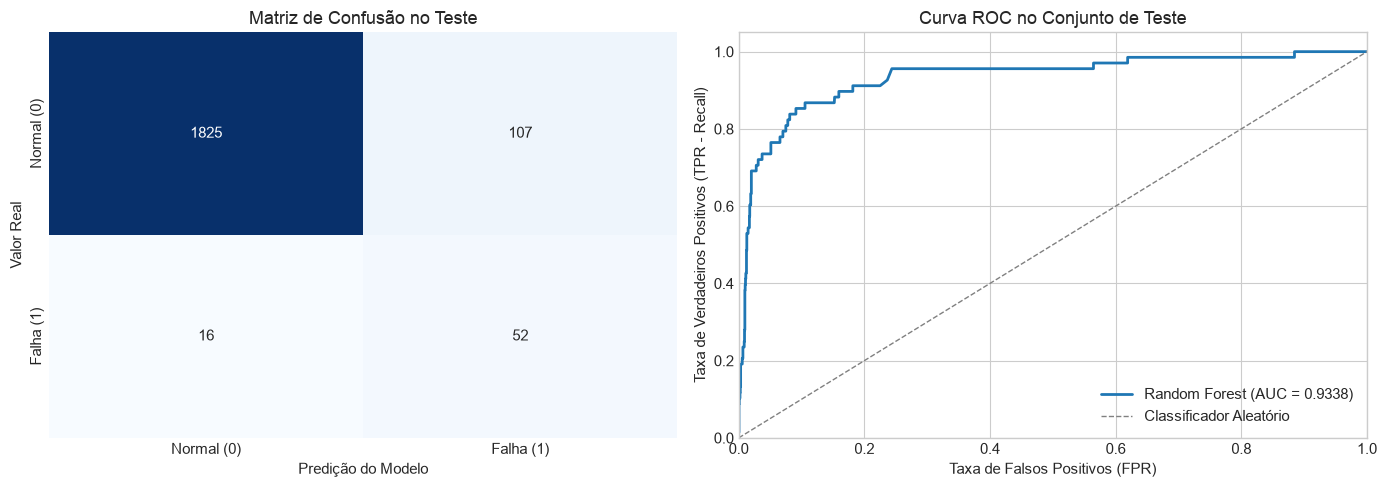

In [9]:
modelo_vencedor_nome = "Random Forest (max_depth=6)"
pipeline_final = resultados_validacao[modelo_vencedor_nome]["pipeline"]

# Avaliação estrita no conjunto de teste
y_pred_test = pipeline_final.predict(X_test)
y_proba_test = pipeline_final.predict_proba(X_test)[:, 1]

acc_test = accuracy_score(y_test, y_pred_test)
rec_test = recall_score(y_test, y_pred_test)
prec_test = precision_score(y_test, y_pred_test)
f1_test = f1_score(y_test, y_pred_test)
auc_test = roc_auc_score(y_test, y_proba_test)
cm_test = confusion_matrix(y_test, y_pred_test)

print("=" * 55)
print(f"RELATÓRIO DE DESEMPENHO NO TESTE — {modelo_vencedor_nome}")
print("=" * 55)
print(f"Acurácia:        {acc_test:.4f}")
print(f"Recall (Falha):  {rec_test:.4f}")
print(f"Precisão:        {prec_test:.4f}")
print(f"F1-Score:        {f1_test:.4f}")
print(f"ROC-AUC:         {auc_test:.4f}")
print("\nRelatório de Classificação Detalhado:")
print(classification_report(y_test, y_pred_test, target_names=["Operação Normal", "Falha"]))

# Plotagem da Matriz de Confusão e Curva ROC
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de Confusão
sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=axes[0],
    xticklabels=["Normal (0)", "Falha (1)"],
    yticklabels=["Normal (0)", "Falha (1)"]
)
axes[0].set_title("Matriz de Confusão no Teste")
axes[0].set_xlabel("Predição do Modelo")
axes[0].set_ylabel("Valor Real")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_proba_test)
axes[1].plot(fpr, tpr, color="#1f77b4", lw=2, label=f"Random Forest (AUC = {auc_test:.4f})")
axes[1].plot([0, 1], [0, 1], color="grey", lw=1, linestyle="--", label="Classificador Aleatório")
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel("Taxa de Falsos Positivos (FPR)")
axes[1].set_ylabel("Taxa de Verdadeiros Positivos (TPR - Recall)")
axes[1].set_title("Curva ROC no Conjunto de Teste")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

## 10. Serialização do Modelo e Registro de Métricas

Para atender rigorosamente aos requisitos das **Fases 1 e 2**, persistimos o artefato binário completo e documentamos as métricas obtidas:
1. `models/modelo_falha.joblib`: O pipeline treinado contendo todo o pré-processamento e o classificador final ajustado.
2. `models/metricas.json`: Relatório estruturado em formato JSON com métricas de validação e teste.
3. **Teste de recarregamento:** Verificação ponta a ponta com leitura do arquivo `.joblib` e predição de um payload sintético representativo.

In [10]:
# 1. Cria o diretório models se não existir
MODELS_DIR = "../models"
os.makedirs(MODELS_DIR, exist_ok=True)

MODEL_FILE = os.path.join(MODELS_DIR, "modelo_falha.joblib")
METRICS_FILE = os.path.join(MODELS_DIR, "metricas.json")

# 2. Salva o pipeline completo com joblib
joblib.dump(pipeline_final, MODEL_FILE)
print(f"Pipeline serializado com sucesso em: {MODEL_FILE}")
print(f"Tamanho do arquivo: {os.path.getsize(MODEL_FILE) / 1024:.1f} KB")

# 3. Salva o relatório de métricas em JSON
metricas_exportadas = {
    "modelo_selecionado": modelo_vencedor_nome,
    "framework": "scikit-learn / imbalanced-learn",
    "split": "Treino 60% / Validação 20% / Teste 20% (Estratificado)",
    "metricas_validacao": {
        "acuracia": float(round(resultados_validacao[modelo_vencedor_nome]["Acurácia"], 4)),
        "recall": float(round(resultados_validacao[modelo_vencedor_nome]["Recall (Falha)"], 4)),
        "precisao": float(round(resultados_validacao[modelo_vencedor_nome]["Precisão"], 4)),
        "f1_score": float(round(resultados_validacao[modelo_vencedor_nome]["F1-Score"], 4)),
        "roc_auc": float(round(resultados_validacao[modelo_vencedor_nome]["ROC-AUC"], 4)),
    },
    "metricas_teste": {
        "acuracia": float(round(acc_test, 4)),
        "recall": float(round(rec_test, 4)),
        "precisao": float(round(prec_test, 4)),
        "f1_score": float(round(f1_test, 4)),
        "roc_auc": float(round(auc_test, 4)),
    },
    "matriz_confusao_teste": cm_test.tolist(),
}

with open(METRICS_FILE, "w", encoding="utf-8") as f:
    json.dump(metricas_exportadas, f, indent=2, ensure_ascii=False)
print(f"Métricas exportadas com sucesso em: {METRICS_FILE}")

# 4. Prova de integridade: Recarrega o modelo e executa inferência de teste
print("\n--- Prova de Integridade (Desserialização) ---")
modelo_recarregado = joblib.load(MODEL_FILE)

amostra_teste = pd.DataFrame([{
    "tipo": "M",
    "temperatura_ar_k": 298.1,
    "temperatura_processo_k": 308.6,
    "velocidade_rotacao_rpm": 1551.0,
    "torque_nm": 42.8,
    "desgaste_ferramenta_min": 0,
}])

pred_classe = int(modelo_recarregado.predict(amostra_teste)[0])
pred_proba = float(modelo_recarregado.predict_proba(amostra_teste)[0][1])

print("Payload de teste:")
print(amostra_teste.to_dict(orient="records")[0])
print(f"\nResultado da predição:")
print(f"Falha prevista: {bool(pred_classe)}")
print(f"Probabilidade estimada de falha: {pred_proba * 100:.2f}%")
print("Modelo pronto para ser servido via API FastAPI!")

Pipeline serializado com sucesso em: ../models/modelo_falha.joblib
Tamanho do arquivo: 826.3 KB
Métricas exportadas com sucesso em: ../models/metricas.json

--- Prova de Integridade (Desserialização) ---
Payload de teste:
{'tipo': 'M', 'temperatura_ar_k': 298.1, 'temperatura_processo_k': 308.6, 'velocidade_rotacao_rpm': 1551.0, 'torque_nm': 42.8, 'desgaste_ferramenta_min': 0}

Resultado da predição:
Falha prevista: False
Probabilidade estimada de falha: 4.45%
Modelo pronto para ser servido via API FastAPI!
